# Don't Miss the Battery: E1 detector comparison (YOLO11-s and RT-DETR-l)
**Group 3 (Bhavyasree Kondi, Bhoomika Lnu, Sanjana Reddy Katham, Sharan Somshekhar Patil), DATA-255**

Trains two more detector families on the **same leak-free split** as the Faster R-CNN runs and scores them
with the **same safety evaluation** (thresholds picked on validation, applied once to test, 95% intervals
that resample whole batteries):

| Model | Family | Weights |
|---|---|---|
| YOLO11-s | one-stage CNN, anchor-free | COCO-pretrained (Ultralytics) |
| RT-DETR-l | transformer, no NMS | COCO-pretrained (Ultralytics) |

Each model uses its standard Ultralytics training recipe (default hyperparameters, mosaic and flip augmentation);
Faster R-CNN results are loaded from the E2 notebook's Drive folder for the side-by-side table.

**Before running:** Runtime > Change runtime type > T4 GPU, then Runtime > Run all (~1.5 h).
Training checkpoints are saved to Drive every epoch, so after a disconnect, Run all again and it resumes.

In [ ]:
!pip -q install ultralytics==8.4.216

In [ ]:
# ---- Config ----
SEED = 42
EPOCHS = 60          # YOLO11-s
EPOCHS_DETR = 30     # RT-DETR-l (about 3x slower per epoch)
IMG_SIZE = 640
IOU_MATCH = 0.5
TARGET_PRECISION = 0.90
MISS_COST = 10
COST_RATIOS = list(range(1, 21))
N_BOOT = 1000
MODELS = {
    "yolo11s":  {"weights": "yolo11s.pt",  "batch": 16, "epochs": "EPOCHS"},
    "rtdetr_l": {"weights": "rtdetr-l.pt", "batch": 8,  "epochs": "EPOCHS_DETR"},
}
DATA_URL = "https://zenodo.org/api/records/15490523/files/recybat24.tar.gz/content"
ROOT = "/content/recybat24"

import os, json, random, time, glob, re, tarfile, math, contextlib, io, urllib.request, shutil
from collections import defaultdict, Counter
import numpy as np
import torch, torchvision
import matplotlib.pyplot as plt

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| device", dev)
if dev.type == "cuda":
    print(torch.cuda.get_device_name(0))
else:
    print("WARNING: no GPU. Runtime > Change runtime type > T4 GPU")

torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | device cuda
Tesla T4


In [ ]:
# ---- Output folder: Google Drive if available, else local disk (zipped for download at the end) ----
try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/dont_miss_the_battery"
except ImportError:
    BASE = "./outputs"
except Exception as e:
    print(f"Drive mount failed ({e}); saving locally instead. Results will be downloaded as a zip at the end.")
    BASE = "/content/outputs"
OUT = os.path.abspath(os.path.join(BASE, "E1_detectors"))   # absolute, so Ultralytics saves exactly here
E2_DIR = os.path.join(BASE, "E2_safety")
os.makedirs(OUT, exist_ok=True)
FIG = os.path.join(OUT, "figures"); os.makedirs(FIG, exist_ok=True)
print("Outputs ->", OUT)

Mounted at /content/drive
Outputs -> /content/drive/MyDrive/dont_miss_the_battery/E1_detectors


In [ ]:
# ---- Download + extract RecyBat24 (Zenodo record 15490523, CC BY-NC-ND 4.0) ----
if not os.path.exists(os.path.join(ROOT, ".done")):
    os.makedirs(ROOT, exist_ok=True)
    tgz = "/content/recybat24.tar.gz"
    if not os.path.exists(tgz):
        print("Downloading ~263 MB ...")
        urllib.request.urlretrieve(DATA_URL, tgz)
    with tarfile.open(tgz) as t:
        try:
            t.extractall(ROOT, filter="data")
        except TypeError:
            t.extractall(ROOT)
    open(os.path.join(ROOT, ".done"), "w").close()

# ---- Detection annotations (the instance-segmentation file repeats every battery 3x, so skip it) ----
coco_files = {}
for p in glob.glob(ROOT + "/**/*.json", recursive=True):
    low = p.lower()
    if "segmentation" in os.path.basename(low):
        continue
    try:
        d = json.load(open(p))
    except Exception:
        continue
    if isinstance(d, dict) and {"images", "annotations", "categories"} <= d.keys():
        if "train" in low:
            coco_files["train"] = p
        elif "val" in low:
            coco_files["val"] = p
assert {"train", "val"} <= coco_files.keys(), coco_files
coco = {k: json.load(open(v)) for k, v in coco_files.items()}
for k, d in coco.items():
    print(k, "| images:", len(d["images"]), "| boxes:", len(d["annotations"]))

img_index = defaultdict(list)
for p in glob.glob(ROOT + "/**/*", recursive=True):
    if p.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
        img_index[os.path.basename(p)].append(p)

def resolve(file_name, split):
    direct = os.path.join(os.path.dirname(coco_files[split]), file_name)
    if os.path.exists(direct):
        return direct
    cands = img_index.get(os.path.basename(file_name), [])
    for c in cands:
        if split in c.lower():
            return c
    if cands:
        return cands[0]
    raise FileNotFoundError(file_name)

used = sorted({a["category_id"] for s in coco.values() for a in s["annotations"]})
cat_names = {c["id"]: c["name"] for c in coco["train"]["categories"]}
cat2label = {cid: i + 1 for i, cid in enumerate(used)}            # 1..K (0 = background)
CLASSES = ["__background__"] + [cat_names.get(cid, str(cid)) for cid in used]
K = len(CLASSES) - 1
print("Classes:", CLASSES[1:])

val | images: 1407 | boxes: 1434
train | images: 1421 | boxes: 1437
Classes: ['cylindric', 'pouch', 'prismatic']


In [ ]:
# ---- Leak-free split (identical to the Faster R-CNN notebooks): released val -> val + test by battery ----
GROUP_REGEX = r"^(\d+)_\d+_(?:[A-Za-z]_)?\d+_([A-Za-z]+)"

def battery_id(fname):
    stem = os.path.splitext(os.path.basename(fname))[0]
    m = re.search(GROUP_REGEX, stem)
    return "_".join(m.groups()) if m else stem

from sklearn.model_selection import StratifiedGroupKFold
val_imgs = coco["val"]["images"]
groups = [battery_id(i["file_name"]) for i in val_imgs]
types = [g.rsplit("_", 1)[-1] for g in groups]
vi, ti = next(StratifiedGroupKFold(n_splits=2, shuffle=True, random_state=SEED).split(val_imgs, types, groups=groups))
val_ids = [val_imgs[i]["id"] for i in vi]
test_ids = [val_imgs[i]["id"] for i in ti]
split_e2 = os.path.join(E2_DIR, "split.json")
if os.path.exists(split_e2):   # use the exact images of the Faster R-CNN runs (immune to scikit-learn version changes)
    s = json.load(open(split_e2)); val_ids, test_ids = s["val_ids"], s["test_ids"]
    print("Loaded the E2 (Faster R-CNN) split from Drive")
bat_of = {i["id"]: battery_id(i["file_name"]) for i in val_imgs}
vb, tb = {bat_of[i] for i in val_ids}, {bat_of[i] for i in test_ids}
assert not (vb & tb) and len(val_ids) + len(test_ids) == len(val_imgs)
print(f"val {len(val_ids)} imgs / {len(vb)} batteries | test {len(test_ids)} imgs / {len(tb)} batteries")
json.dump({"val_ids": val_ids, "test_ids": test_ids, "seed": SEED}, open(os.path.join(OUT, "split.json"), "w"))

Loaded the E2 (Faster R-CNN) split from Drive
val 702 imgs / 47 batteries | test 705 imgs / 47 batteries


In [ ]:
# ---- Ground truth access (same class as the Faster R-CNN notebooks, used for evaluation) ----
class BatteryDet:
    def __init__(self, split, img_ids=None):
        d = coco[split]
        self.split = split
        self.imgs = {i["id"]: i for i in d["images"]}
        self.ids = list(img_ids) if img_ids is not None else list(self.imgs)
        self.anns = defaultdict(list)
        for a in d["annotations"]:
            self.anns[a["image_id"]].append(a)

    def __len__(self):
        return len(self.ids)

    def gt(self, iid):
        boxes, labels = [], []
        for a in self.anns[iid]:
            x, y, w, h = a["bbox"]
            if w >= 1 and h >= 1:
                boxes.append([x, y, x + w, y + h]); labels.append(cat2label[a["category_id"]])
        return np.array(boxes, np.float32).reshape(-1, 4), np.array(labels, np.int64)

    def battery(self, iid):
        return battery_id(self.imgs[iid]["file_name"])

    def path(self, iid):
        return resolve(self.imgs[iid]["file_name"], self.split)

train_ds = BatteryDet("train")
val_ds = BatteryDet("val", val_ids)
test_ds = BatteryDet("val", test_ids)
print(len(train_ds), len(val_ds), len(test_ds))

1421 702 705


In [ ]:
# ---- Export the split in YOLO format (links, no copies). Class index = label - 1. ----
YDIR = "/content/yolo_recybat" if os.path.isdir("/content") else os.path.abspath("./yolo_recybat")
shutil.rmtree(YDIR, ignore_errors=True)
yolo_name = {}            # (split, image id) -> exported file name

def export(ds, sub):
    os.makedirs(f"{YDIR}/{sub}/images", exist_ok=True); os.makedirs(f"{YDIR}/{sub}/labels", exist_ok=True)
    for iid in ds.ids:
        src = ds.path(iid); info = ds.imgs[iid]
        name = f"{iid}_{os.path.basename(src)}"
        dst = f"{YDIR}/{sub}/images/{name}"
        try:
            os.symlink(os.path.abspath(src), dst)
        except OSError:
            shutil.copy(src, dst)
        W, H = info.get("width", IMG_SIZE), info.get("height", IMG_SIZE)
        b, l = ds.gt(iid)
        with open(f"{YDIR}/{sub}/labels/{os.path.splitext(name)[0]}.txt", "w") as f:
            for (x1, y1, x2, y2), c in zip(b, l):
                f.write(f"{c - 1} {(x1 + x2) / 2 / W:.6f} {(y1 + y2) / 2 / H:.6f} {(x2 - x1) / W:.6f} {(y2 - y1) / H:.6f}\n")
        yolo_name[(sub, iid)] = dst

for ds, sub in [(train_ds, "train"), (val_ds, "val"), (test_ds, "test")]:
    export(ds, sub)
DATA_YAML = f"{YDIR}/data.yaml"
with open(DATA_YAML, "w") as f:
    f.write(f"path: {YDIR}\ntrain: train/images\nval: val/images\ntest: test/images\n")
    f.write("names:\n" + "".join(f"  {i}: {n}\n" for i, n in enumerate(CLASSES[1:])))
print({sub: len(os.listdir(f"{YDIR}/{sub}/images")) for sub in ["train", "val", "test"]})

{'train': 1421, 'val': 702, 'test': 705}


In [ ]:
# ---- COCO metrics (identical to the Faster R-CNN notebooks) ----
from torchvision.ops import box_iou, nms
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

def make_gt(ds):
    images, anns = [], []
    for iid in ds.ids:
        info = ds.imgs[iid]
        images.append({"id": iid, "width": info.get("width", IMG_SIZE), "height": info.get("height", IMG_SIZE)})
        b, l = ds.gt(iid)
        for bb, ll in zip(b, l):
            w, h = float(bb[2] - bb[0]), float(bb[3] - bb[1])
            anns.append({"id": len(anns) + 1, "image_id": iid, "category_id": int(ll),
                         "bbox": [float(bb[0]), float(bb[1]), w, h], "area": w * h, "iscrowd": 0})
    c = COCO()
    c.dataset = {"images": images, "annotations": anns,
                 "categories": [{"id": i, "name": n} for i, n in enumerate(CLASSES) if i > 0]}
    with contextlib.redirect_stdout(io.StringIO()):
        c.createIndex()
    return c

def coco_metrics(preds, gt):
    res = [{"image_id": iid, "category_id": int(l), "score": float(s),
            "bbox": [float(b[0]), float(b[1]), float(b[2] - b[0]), float(b[3] - b[1])]}
           for iid, p in preds.items() for b, s, l in zip(p["boxes"], p["scores"], p["labels"])]
    if not res:
        return {"mAP50_95": 0.0, "mAP50": 0.0, "mAP75": 0.0, "per_class": {}}
    with contextlib.redirect_stdout(io.StringIO()):
        E = COCOeval(gt, gt.loadRes(res), "bbox"); E.evaluate(); E.accumulate(); E.summarize()
    prec = E.eval["precision"]
    ap = lambda p: float(p[p > -1].mean()) if (p > -1).any() else float("nan")
    per_class = {CLASSES[k + 1]: {"AP50_95": ap(prec[:, :, k, 0, -1]), "AP50": ap(prec[0, :, k, 0, -1])} for k in range(K)}
    return {"mAP50_95": float(E.stats[0]), "mAP50": float(E.stats[1]), "mAP75": float(E.stats[2]), "per_class": per_class}

In [ ]:
# ---- Safety evaluation (identical to the Faster R-CNN notebooks) ----
THS = np.round(np.arange(0.01, 1.0, 0.01), 2)

def match(preds, ds, class_aware):
    G = {"score": [], "cls": [], "pred": [], "bat": []}
    FA = {"score": [], "label": [], "bat": []}
    for iid in ds.ids:
        gb, gl = ds.gt(iid); bat = ds.battery(iid)
        p = preds[iid]; pb, ps, pl = torch.from_numpy(p["boxes"]), torch.from_numpy(p["scores"]), p["labels"]
        if not class_aware and len(pb):
            keep = nms(pb, ps, 0.5); pb, ps, pl = pb[keep], ps[keep], pl[keep.numpy()]
        ious = box_iou(pb, torch.from_numpy(gb)).numpy() if len(gb) and len(pb) else np.zeros((len(pb), len(gb)))
        g_score = np.full(len(gb), -1.0); g_pred = np.zeros(len(gb), int)
        for j in torch.argsort(ps, descending=True).numpy():
            cand = ious[j].copy(); cand[g_score >= 0] = -1
            if class_aware:
                cand[gl != pl[j]] = -1
            k = int(cand.argmax()) if len(gb) else -1
            if k >= 0 and cand[k] >= IOU_MATCH:
                g_score[k] = float(ps[j]); g_pred[k] = int(pl[j])
            else:
                FA["score"].append(float(ps[j])); FA["label"].append(int(pl[j])); FA["bat"].append(bat)
        G["score"] += g_score.tolist(); G["cls"] += gl.tolist(); G["pred"] += g_pred.tolist(); G["bat"] += [bat] * len(gb)
    return {k: np.array(v) for k, v in G.items()}, {k: np.array(v) for k, v in FA.items()}

def counts(G, FA, t):
    tp = int((G["score"] >= t).sum()); fp = int((FA["score"] >= t).sum()); n = len(G["score"])
    fn = n - tp
    prec = tp / max(tp + fp, 1); rec = tp / max(n, 1)
    return {"thr": float(t), "tp": tp, "fp": fp, "fn": fn, "n": n, "precision": prec, "recall": rec,
            "f1": 2 * prec * rec / max(prec + rec, 1e-9), "miss_rate": fn / max(n, 1)}

def pick_threshold_precision(G, FA):
    rows = [counts(G, FA, t) for t in THS]
    ok = [r for r in rows if r["precision"] >= TARGET_PRECISION]
    best = min(ok, key=lambda r: (r["miss_rate"], -r["precision"])) if ok else max(rows, key=lambda r: r["precision"])
    return best["thr"]

def pick_threshold_cost(G, FA, c):
    return min(THS, key=lambda t: (lambda r: c * r["fn"] + r["fp"])(counts(G, FA, t)))

def bootstrap_miss(G, FA, t, seed=SEED):
    bats = np.unique(G["bat"])
    per = {b: (int(((G["bat"] == b) & (G["score"] >= t)).sum()), int((G["bat"] == b).sum()),
               int(((FA["bat"] == b) & (FA["score"] >= t)).sum())) for b in bats}
    rng = np.random.default_rng(seed); miss, prec = [], []
    for _ in range(N_BOOT):
        s = rng.choice(bats, len(bats), replace=True)
        tp = sum(per[b][0] for b in s); n = sum(per[b][1] for b in s); fp = sum(per[b][2] for b in s)
        miss.append(1 - tp / max(n, 1)); prec.append(tp / max(tp + fp, 1))
    out = {"miss_ci": [float(np.percentile(miss, 2.5)), float(np.percentile(miss, 97.5))],
           "precision_ci": [float(np.percentile(prec, 2.5)), float(np.percentile(prec, 97.5))],
           "n_batteries": int(len(bats))}
    if counts(G, FA, t)["fn"] == 0:
        out["miss_upper95_zero_events"] = float(1 - 0.05 ** (1 / len(bats)))
    return out

def ece(G, FA, min_score=0.05, bins=10):
    s = np.concatenate([G["score"][G["score"] >= min_score], FA["score"][FA["score"] >= min_score]])
    y = np.concatenate([np.ones((G["score"] >= min_score).sum()), np.zeros((FA["score"] >= min_score).sum())])
    edges = np.linspace(min_score, 1, bins + 1); e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        b = (s >= lo) & ((s < hi) | (hi == 1))
        if b.any():
            e += b.mean() * abs(y[b].mean() - s[b].mean())
    return float(e)

def confusion(G, FA, t):
    cm = np.zeros((K + 1, K + 1), int)
    for sc, c, p in zip(G["score"], G["cls"], G["pred"]):
        cm[c - 1, p - 1 if sc >= t else K] += 1
    for sc, l in zip(FA["score"], FA["label"]):
        if sc >= t:
            cm[K, l - 1] += 1
    return cm

def safety_report(val_preds, test_preds):
    rep = {}
    for mode in ["class_agnostic", "class_aware"]:
        Gv, Fv = match(val_preds, val_ds, mode == "class_aware")
        Gt, Ft = match(test_preds, test_ds, mode == "class_aware")
        t90 = pick_threshold_precision(Gv, Fv)
        r = {"thr_from_val": t90, "test_at_thr": counts(Gt, Ft, t90), **bootstrap_miss(Gt, Ft, t90),
             "cost": {}, "ece": ece(Gt, Ft)}
        for c in COST_RATIOS:
            tc = pick_threshold_cost(Gv, Fv, c); ct = counts(Gt, Ft, tc)
            r["cost"][c] = {"thr_from_val": float(tc), "cwe_per_battery": (c * ct["fn"] + ct["fp"]) / max(ct["n"], 1),
                            "miss_rate": ct["miss_rate"], "precision": ct["precision"], "fp": ct["fp"], "fn": ct["fn"]}
        r["pr_curve_test"] = [counts(Gt, Ft, t) for t in THS]
        if mode == "class_agnostic":
            cm = confusion(Gt, Ft, t90); r["confusion"] = cm.tolist()
            r["per_class_miss"] = {CLASSES[c]: float(((Gt["cls"] == c) & (Gt["score"] < t90)).sum() / max((Gt["cls"] == c).sum(), 1))
                                   for c in range(1, K + 1)}
            pi, po = CLASSES.index("prismatic") if "prismatic" in CLASSES else None, CLASSES.index("pouch") if "pouch" in CLASSES else None
            if pi and po:
                r["prismatic_as_pouch"] = float(cm[pi - 1, po - 1] / max(cm[pi - 1].sum(), 1))
                r["pouch_as_prismatic"] = float(cm[po - 1, pi - 1] / max(cm[po - 1].sum(), 1))
        rep[mode] = r
    return rep

val_gt, test_gt = make_gt(val_ds), make_gt(test_ds)

In [ ]:
# ---- Train (resumable from Drive) and predict ----
from ultralytics import YOLO, RTDETR

def run_dir(name):
    return os.path.join(OUT, name)

def train_model(name, cfg):
    wdir = os.path.join(run_dir(name), "weights")
    done_flag = os.path.join(run_dir(name), "TRAINING_DONE")
    Model = RTDETR if name.startswith("rtdetr") else YOLO
    last = os.path.join(wdir, "last.pt")
    if not os.path.exists(done_flag) and os.path.exists(last):
        ck = torch.load(last, map_location="cpu", weights_only=False)
        if ck.get("epoch", -1) == -1 or ck.get("optimizer") is None:   # Ultralytics marks a finished run this way
            open(done_flag, "w").close()
        del ck
    if os.path.exists(done_flag):
        print(f"[{name}] training already finished, loading best.pt")
    elif os.path.exists(last):
        print(f"[{name}] resuming from last.pt")
        m = Model(last); m.train(resume=True)
        assert os.path.samefile(m.trainer.save_dir, run_dir(name)), m.trainer.save_dir
        open(done_flag, "w").close()
    else:
        set_seed(SEED)
        m = Model(cfg["weights"])
        m.train(data=DATA_YAML, epochs=globals()[cfg["epochs"]], imgsz=IMG_SIZE, batch=cfg["batch"], seed=SEED,
                deterministic=True, workers=2, project=OUT, name=name, exist_ok=True, device=0 if dev.type == "cuda" else "cpu",
                amp=dev.type == "cuda", plots=True, verbose=False, patience=100)
        assert os.path.samefile(m.trainer.save_dir, run_dir(name)), m.trainer.save_dir
        open(done_flag, "w").close()
    return Model(os.path.join(wdir, "best.pt"))

def predict(model, ds, sub, bs=16):
    """conf 0.001 / max 100 boxes, matching the Faster R-CNN evaluation. Labels shifted to 1..K."""
    preds, ids = {}, list(ds.ids)
    for i in range(0, len(ids), bs):
        chunk = ids[i:i + bs]
        res = model.predict([yolo_name[(sub, iid)] for iid in chunk], imgsz=IMG_SIZE, conf=0.001, iou=0.7,
                            max_det=100, verbose=False, device=0 if dev.type == "cuda" else "cpu")
        for iid, r in zip(chunk, res):
            b = r.boxes
            preds[iid] = {"boxes": b.xyxy.cpu().numpy().astype(np.float32), "scores": b.conf.cpu().numpy().astype(np.float32),
                          "labels": b.cls.cpu().numpy().astype(np.int64) + 1}
    return preds

results = {}
for name, cfg in MODELS.items():
    res_path = os.path.join(OUT, f"results_{name}.json")
    if os.path.exists(res_path):
        results[name] = json.load(open(res_path)); print(f"[{name}] already done, loaded results"); continue
    t0 = time.time()
    model = train_model(name, cfg)
    train_min = (time.time() - t0) / 60
    val_preds, test_preds = predict(model, val_ds, "val"), predict(model, test_ds, "test")
    results[name] = {"config": cfg, "train_minutes_this_session": train_min,
                     "test_coco": coco_metrics(test_preds, test_gt), "val_coco": coco_metrics(val_preds, val_gt),
                     "safety": safety_report(val_preds, test_preds)}
    hist = os.path.join(run_dir(name), "results.csv")
    if os.path.exists(hist):
        results[name]["history_csv"] = open(hist).read()
    json.dump(results[name], open(res_path, "w"), indent=1, default=float)
    s = results[name]["safety"]
    print(f"[{name}] TEST mAP50 {results[name]['test_coco']['mAP50']:.3f} | "
          f"type-aware miss @P>=0.9 {s['class_aware']['test_at_thr']['miss_rate']:.3f} "
          f"{[round(x, 3) for x in s['class_aware']['miss_ci']]} | prismatic->pouch {s['class_agnostic'].get('prismatic_as_pouch', float('nan')):.3f}")
    del model
    if dev.type == "cuda":
        torch.cuda.empty_cache()

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_recybat/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0,

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       1/30      6.84G     0.3254      4.445     0.2212          9        640: 100% ━━━━━━━━━━━━ 178/178 1.7it/s 1:47
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 44/44 2.7it/s 16.5s
                   all        702        729      0.849      0.854      0.928      0.804

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
       2/30      7.23G     0.2201      0.324     0.1406         14        640: 0% ──────────── 0/178  0.6s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       2/30      7.23G     0.2242     0.4259     0.1336          9        640: 100% ━━━━━━━━━━━━ 178/178 1.8it/s 1:42
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 44/44 2.8it/s 15.9s
                   all        702        729      0.827      0.804      0.852       0.74

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
       3/30      7.28G     0.1823     0.2763     0.1208         10        640: 0% ──────────── 0/178  0.6s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (51 outputs left out)

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      29/30      7.28G    0.09388     0.1776    0.05484          5        640: 100% ━━━━━━━━━━━━ 178/178 1.8it/s 1:42
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 44/44 2.8it/s 15.8s
                   all        702        729      0.966      0.918      0.965      0.863

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      30/30      7.28G     0.1157     0.2115    0.06572          9        640: 0% ──────────── 0/178  0.6s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      30/30      7.28G    0.09272     0.1801    0.05493          5        640: 100% ━━━━━━━━━━━━ 178/178 1.7it/s 1:42
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 44/44 2.8it/s 15.8s
                   all        702        729      0.966      0.921      0.963      0.868

30 epochs completed in 1.022 hours.
Optimizer stripped from /content/drive/MyDrive/dont_miss_the_battery/E1_detectors/rtdetr_l/weights/last.pt, 66.2MB
Optimizer stripped from /content/drive/MyDrive/dont_miss_the_battery/E1_detectors/rtdetr_l/weights/best.pt, 66.2MB

Validating /content/drive/MyDrive/dont_miss_the_battery/E1_detectors/rtdetr_l/weights/best.pt...
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
rt-detr-l summary (fused): 315 layers, 31,989,905 parameters, 0 gradients, 105.3 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 44/44 2.7it/s 16.4s


In [ ]:
# ---- Model cost: parameters, GFLOPs, speed (fp32, batch 1, same method as Faster R-CNN) ----
from torch.utils.flop_counter import FlopCounterMode
costs = {}
import cv2
sample = [cv2.imread(yolo_name[("test", iid)]) for iid in test_ds.ids[:100]]   # BGR uint8, as Ultralytics expects
for name in MODELS:
    m = (RTDETR if name.startswith("rtdetr") else YOLO)(os.path.join(run_dir(name), "weights", "best.pt"))
    net = m.model.float().to(dev).eval()
    n_params = sum(p.numel() for p in net.parameters())
    with torch.no_grad(), FlopCounterMode(display=False) as fc:
        net(torch.zeros(1, 3, IMG_SIZE, IMG_SIZE, device=dev))
    gflops = fc.get_total_flops() / 1e9
    kw = dict(imgsz=IMG_SIZE, conf=0.001, max_det=100, verbose=False, device=0 if dev.type == "cuda" else "cpu")
    for im in sample[:10]:
        m.predict(im, **kw)
    if dev.type == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for im in sample:
        m.predict(im, **kw)
    if dev.type == "cuda": torch.cuda.synchronize()
    costs[name] = {"params_M": n_params / 1e6, "GFLOPs": gflops, "fps_batch1_fp32": len(sample) / (time.time() - t0)}
    print(f"{name}: {costs[name]['params_M']:.1f} M params | {gflops:.1f} GFLOPs | {costs[name]['fps_batch1_fp32']:.1f} FPS")
json.dump(costs, open(os.path.join(OUT, "model_cost.json"), "w"), indent=1)

yolo11s: 9.4 M params | 21.4 GFLOPs | 84.4 FPS
rtdetr_l: 32.8 M params | 109.2 GFLOPs | 22.9 FPS


In [ ]:
# ---- Bring in the Faster R-CNN results from E2 for the side-by-side comparison ----
allres, allcost = {}, {}
for n, label in [("baseline", "frcnn"), ("repeat_factor", "frcnn_rfs")]:
    p = os.path.join(E2_DIR, f"results_{n}.json")
    if os.path.exists(p):
        allres[label] = json.load(open(p))
        if os.path.exists(os.path.join(E2_DIR, "model_cost.json")):
            allcost[label] = json.load(open(os.path.join(E2_DIR, "model_cost.json")))
    else:
        print(f"(E2 result {p} not found; Faster R-CNN left out of the comparison)")
allres.update(results); allcost.update(costs)

def cost_of(r, c):
    d = r["safety"]["class_aware"]["cost"]
    return d[c] if c in d else d[str(c)]

names = list(allres)
rows = []
for n in names:
    r = allres[n]; ag, aw = r["safety"]["class_agnostic"], r["safety"]["class_aware"]
    rows.append({
        "model": n, "mAP50": r["test_coco"]["mAP50"], "mAP50_95": r["test_coco"]["mAP50_95"],
        **{f"AP50_{c}": r["test_coco"]["per_class"][c]["AP50"] for c in CLASSES[1:] if c in r["test_coco"]["per_class"]},
        "any_miss@P90": ag["test_at_thr"]["miss_rate"], "any_miss_CI": ag["miss_ci"],
        "type_miss@P90": aw["test_at_thr"]["miss_rate"], "type_miss_CI": aw["miss_ci"],
        "type_precision": aw["test_at_thr"]["precision"], "type_F1": aw["test_at_thr"]["f1"], "thr": aw["thr_from_val"],
        "type_CWE@10": cost_of(r, MISS_COST)["cwe_per_battery"],
        "prism_as_pouch": ag.get("prismatic_as_pouch"), "pouch_as_prism": ag.get("pouch_as_prismatic"), "ECE": aw["ece"],
        **{k: allcost.get(n, {}).get(k) for k in ["params_M", "GFLOPs", "fps_batch1_fp32"]},
    })
json.dump(rows, open(os.path.join(OUT, "E1_summary.json"), "w"), indent=1, default=float)
hdr = (f"{'model':11s} {'mAP50':>6s} {'mAP':>6s} {'anyMiss':>8s} {'typeMiss':>9s} {'95% CI':>15s} {'prec':>6s} "
       f"{'CWE10':>6s} {'pr->po':>7s} {'ECE':>6s} {'GFLOPs':>7s} {'FPS':>6s}")
print(hdr); print("-" * len(hdr))
for r in rows:
    print(f"{r['model']:11s} {r['mAP50']:6.3f} {r['mAP50_95']:6.3f} {r['any_miss@P90']:8.3f} {r['type_miss@P90']:9.3f} "
          f"[{r['type_miss_CI'][0]:.3f},{r['type_miss_CI'][1]:.3f}] {r['type_precision']:6.3f} {r['type_CWE@10']:6.3f} "
          f"{(r['prism_as_pouch'] or 0):7.3f} {r['ECE']:6.3f} {(r['GFLOPs'] or 0):7.1f} {(r['fps_batch1_fp32'] or 0):6.1f}")

model        mAP50    mAP  anyMiss  typeMiss          95% CI   prec  CWE10  pr->po    ECE  GFLOPs    FPS
--------------------------------------------------------------------------------------------------------
frcnn        0.975  0.869    0.000     0.028 [0.000,0.085]  0.954  0.340   0.156  0.036   181.4   17.4
frcnn_rfs    0.977  0.873    0.000     0.024 [0.000,0.072]  0.940  0.313   0.141  0.036   181.4   17.4
yolo11s      0.965  0.891    0.000     0.023 [0.000,0.065]  0.943  0.264   0.156  0.087    21.4   84.4
rtdetr_l     0.996  0.927    0.000     0.000 [0.000,0.000]  0.939  0.065   0.000  0.061   109.2   22.9


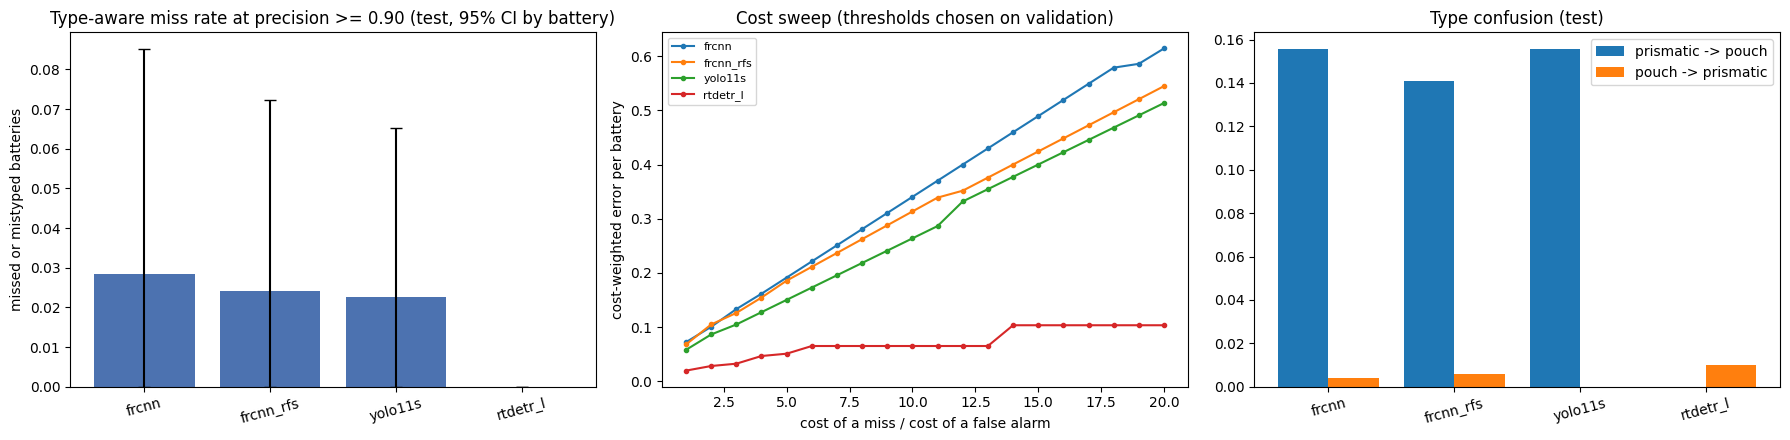

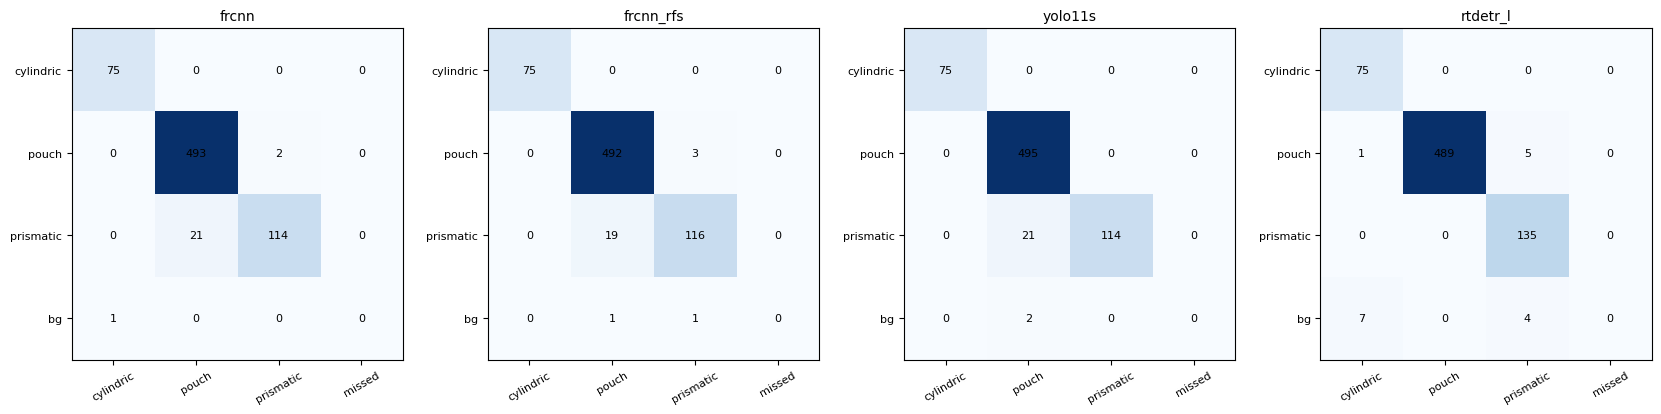

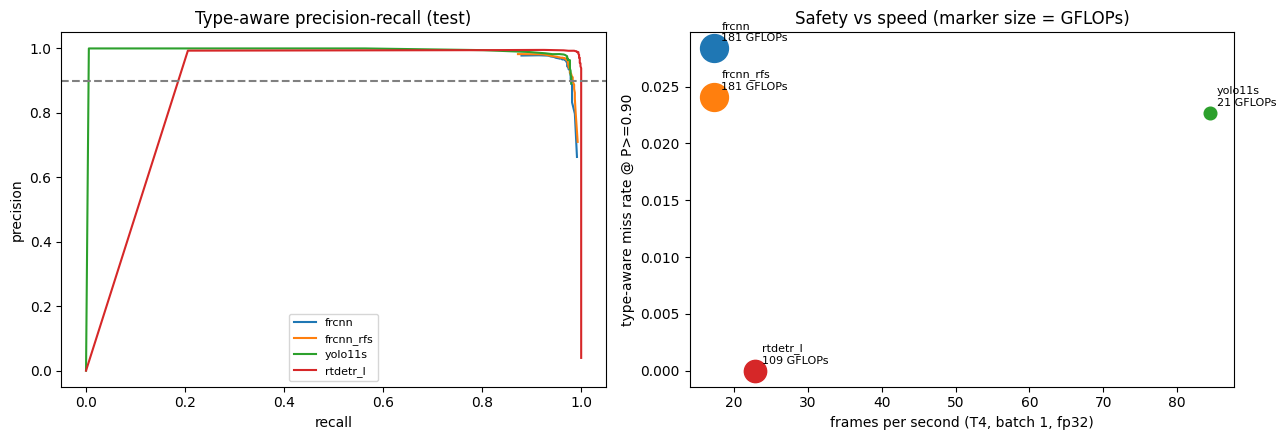

In [ ]:
# ---- Figures ----
x = np.arange(len(names))
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
mr = [r["type_miss@P90"] for r in rows]
err = np.array([[r["type_miss@P90"] - r["type_miss_CI"][0], r["type_miss_CI"][1] - r["type_miss@P90"]] for r in rows]).T
ax[0].bar(x, mr, yerr=np.clip(err, 0, None), capsize=4, color="#4C72B0")
ax[0].set_xticks(x); ax[0].set_xticklabels(names, rotation=15); ax[0].set_ylabel("missed or mistyped batteries")
ax[0].set_title("Type-aware miss rate at precision >= 0.90 (test, 95% CI by battery)")
for n in names:
    ax[1].plot(COST_RATIOS, [cost_of(allres[n], c)["cwe_per_battery"] for c in COST_RATIOS], "o-", ms=3, label=n)
ax[1].set_xlabel("cost of a miss / cost of a false alarm"); ax[1].set_ylabel("cost-weighted error per battery")
ax[1].set_title("Cost sweep (thresholds chosen on validation)"); ax[1].legend(fontsize=8)
ax[2].bar(x - 0.2, [r["prism_as_pouch"] or 0 for r in rows], 0.4, label="prismatic -> pouch")
ax[2].bar(x + 0.2, [r["pouch_as_prism"] or 0 for r in rows], 0.4, label="pouch -> prismatic")
ax[2].set_xticks(x); ax[2].set_xticklabels(names, rotation=15); ax[2].legend(); ax[2].set_title("Type confusion (test)")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "E1_comparison.png"), dpi=130); plt.show()

fig, axes = plt.subplots(1, len(names), figsize=(4.2 * len(names), 4))
labels = CLASSES[1:] + ["bg"]
for ax_, n in zip(np.atleast_1d(axes), names):
    cm = np.array(allres[n]["safety"]["class_agnostic"]["confusion"])
    ax_.imshow(cm, cmap="Blues")
    for i in range(K + 1):
        for j in range(K + 1):
            ax_.text(j, i, cm[i, j], ha="center", va="center", fontsize=8)
    ax_.set_xticks(range(K + 1)); ax_.set_xticklabels(labels[:-1] + ["missed"], rotation=30, fontsize=8)
    ax_.set_yticks(range(K + 1)); ax_.set_yticklabels(labels, fontsize=8); ax_.set_title(n, fontsize=10)
plt.tight_layout(); plt.savefig(os.path.join(FIG, "E1_confusion_matrices.png"), dpi=130); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for n in names:
    pr = allres[n]["safety"]["class_aware"]["pr_curve_test"]
    ax[0].plot([p["recall"] for p in pr], [p["precision"] for p in pr], label=n)
ax[0].axhline(TARGET_PRECISION, ls="--", c="gray"); ax[0].set_xlabel("recall"); ax[0].set_ylabel("precision")
ax[0].set_title("Type-aware precision-recall (test)"); ax[0].legend(fontsize=8)
for r in rows:
    if r["fps_batch1_fp32"]:
        ax[1].scatter(r["fps_batch1_fp32"], r["type_miss@P90"], s=40 + 2 * (r["GFLOPs"] or 0))
        ax[1].annotate(f"{r['model']}\n{r['GFLOPs']:.0f} GFLOPs", (r["fps_batch1_fp32"], r["type_miss@P90"]), fontsize=8,
                       xytext=(5, 5), textcoords="offset points")
ax[1].set_xlabel("frames per second (T4, batch 1, fp32)"); ax[1].set_ylabel("type-aware miss rate @ P>=0.90")
ax[1].set_title("Safety vs speed (marker size = GFLOPs)")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "E1_pr_and_speed.png"), dpi=130); plt.show()

In [ ]:
# ---- Zip results + figures (weights stay in OUT/<model>/weights) and download ----
pack = "/content/E1_results" if os.path.isdir("/content") else "./E1_results"
os.makedirs(pack, exist_ok=True)
for f in os.listdir(OUT):
    if f.endswith(".json"):
        shutil.copy(os.path.join(OUT, f), pack)
shutil.copytree(FIG, os.path.join(pack, "figures"), dirs_exist_ok=True)
for name in MODELS:   # Ultralytics training curves
    for f in ["results.csv", "results.png"]:
        p = os.path.join(run_dir(name), f)
        if os.path.exists(p):
            shutil.copy(p, os.path.join(pack, f"{name}_{f}"))
zip_path = shutil.make_archive(pack, "zip", pack)
print("Results zip:", zip_path, "| weights kept in", OUT)
try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    pass

Results zip: /content/E1_results.zip | weights kept in /content/drive/MyDrive/dont_miss_the_battery/E1_detectors


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>